# Element Composition Comparison Across Molecular Datasets

## Objective

This analysis compares the types and frequencies of chemical elements present in the candidate molecular datasets.

The goal is to determine how similar the elemental compositions of the datasets are before combining them for model training. Large differences in elemental composition may indicate that the datasets represent different regions of chemical space.

Datasets analyzed:
- ChEMBL's BACE (filtered)
- Tox21
- ClinTox

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from rdkit import Chem
from collections import Counter

## Load and Prepare Datasets

In [3]:
chembl_bace_df = pd.read_csv("data/chembl_bace1_ic50_raw.csv")
tox21_df = pd.read_csv("data/tox21.csv.gz")
clintox_df = pd.read_csv("data/clintox.csv.gz")

print("Raw ChEMBL BACE-1 shape:", chembl_bace_df.shape)
print("Tox21 shape:", tox21_df.shape)
print("ClinTox shape:", clintox_df.shape)

Raw ChEMBL BACE-1 shape: (13777, 47)
Tox21 shape: (7831, 14)
ClinTox shape: (1484, 3)


In [4]:
chembl_clean = chembl_bace_df[
    (chembl_bace_df["standard_relation"] == "=") &
    (chembl_bace_df["standard_value"].notna()) &
    (chembl_bace_df["standard_units"] == "nM") &
    (chembl_bace_df["canonical_smiles"].notna()) &
    (chembl_bace_df["data_validity_comment"].isna()) &
    (chembl_bace_df["potential_duplicate"] == 0) &
    (chembl_bace_df["assay_type"] == "B")
].copy()

print("Raw ChEMBL records:", len(chembl_bace_df))
print("Records after quality filtering:", len(chembl_clean))
print("Unique ChEMBL molecules:", chembl_clean["molecule_chembl_id"].nunique())

Raw ChEMBL records: 13777
Records after quality filtering: 10631
Unique ChEMBL molecules: 8117


In [5]:
import numpy as np

chembl_clean["pIC50"] = 9 - np.log10(chembl_clean["standard_value"])

chembl_molecule_df = (
    chembl_clean
    .groupby("molecule_chembl_id", as_index=False)
    .agg({
        "canonical_smiles": "first",
        "pIC50": "median"
    })
)

print("Final ChEMBL molecule-level size:", len(chembl_molecule_df))
chembl_molecule_df.head()

Final ChEMBL molecule-level size: 8117


,molecule_chembl_id,canonical_smiles,pIC50
0,CHEMBL1076901,CC(C)[C@H](NC(=O)[C@H](C)C[C@H](O)[C@H](COCc1c...,7.221849
1,CHEMBL1076902,CC(C)[C@H](NC(=O)[C@H](C)C[C@H](O)[C@H](COCc1c...,6.763622
2,CHEMBL1076905,CC(C)[C@H](NC(=O)[C@H](C)C[C@H](O)[C@H](COc1cc...,7.652259
3,CHEMBL1076906,CC(C)[C@H](NC(=O)[C@@H](C)C[C@H](O)[C@H](COc1c...,7.234261
4,CHEMBL1076907,CSCC[C@H](NC(=O)[C@@H](NC(=O)OC(C)(C)C)C(C)C)C...,5.000000


In [6]:
print("ChEMBL columns:")
print(chembl_molecule_df.columns.tolist())

print("\nTox21 columns:")
print(tox21_df.columns.tolist())

print("\nClinTox columns:")
print(clintox_df.columns.tolist())

ChEMBL columns:
['molecule_chembl_id', 'canonical_smiles', 'pIC50']

Tox21 columns:
['NR-AR', 'NR-AR-LBD', 'NR-AhR', 'NR-Aromatase', 'NR-ER', 'NR-ER-LBD', 'NR-PPAR-gamma', 'SR-ARE', 'SR-ATAD5', 'SR-HSE', 'SR-MMP', 'SR-p53', 'mol_id', 'smiles']

ClinTox columns:
['smiles', 'FDA_APPROVED', 'CT_TOX']


In [7]:
display(chembl_molecule_df.head())
display(tox21_df.head())
display(clintox_df.head())

,molecule_chembl_id,canonical_smiles,pIC50
0,CHEMBL1076901,CC(C)[C@H](NC(=O)[C@H](C)C[C@H](O)[C@H](COCc1c...,7.221849
1,CHEMBL1076902,CC(C)[C@H](NC(=O)[C@H](C)C[C@H](O)[C@H](COCc1c...,6.763622
2,CHEMBL1076905,CC(C)[C@H](NC(=O)[C@H](C)C[C@H](O)[C@H](COc1cc...,7.652259
3,CHEMBL1076906,CC(C)[C@H](NC(=O)[C@@H](C)C[C@H](O)[C@H](COc1c...,7.234261
4,CHEMBL1076907,CSCC[C@H](NC(=O)[C@@H](NC(=O)OC(C)(C)C)C(C)C)C...,5.000000


,NR-AR,NR-AR-LBD,NR-AhR,NR-Aromatase,NR-ER,NR-ER-LBD,NR-PPAR-gamma,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53,mol_id,smiles
0,0.0,0.0,1.0,NaN,NaN,0.0,0.0,1.0,0.0,0.0,0.0,0.0,TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0,TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,TOX3024,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0,TOX3027,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,TOX20800,CC(O)(P(=O)(O)O)P(=O)(O)O


,smiles,FDA_APPROVED,CT_TOX
0,*C(=O)[C@H](CCCCNC(=O)OCCOC)NC(=O)OCCOC,1,0
1,[C@@H]1([C@@H]([C@@H]([C@H]([C@@H]([C@@H]1Cl)C...,1,0
2,[C@H]([C@@H]([C@@H](C(=O)[O-])O)O)([C@H](C(=O)...,1,0
3,[H]/[NH+]=C(/C1=CC(=O)/C(=C\C=c2ccc(=C([NH3+])...,1,0
4,[H]/[NH+]=C(\N)/c1ccc(cc1)OCCCCCOc2ccc(cc2)/C(...,1,0


## Extract Elements from SMILES

Each SMILES string is converted into an RDKit molecule, and the element symbol of each atom is extracted.

This allows comparison of the elemental composition of the ChEMBL BACE-1, Tox21, and ClinTox datasets.

In [21]:
def get_elements(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    return [
        atom.GetSymbol()
        for atom in mol.GetAtoms()
        if atom.GetAtomicNum() > 0
    ]

In [23]:
#quick test 2 double check the function works

test_smiles = [
    "CCO",
    "CC(=O)O",
    "c1ccccc1",
    "CCCl"
]

for smiles in test_smiles:
    print(smiles, "->", get_elements(smiles))

CCO -> ['C', 'C', 'O']
CC(=O)O -> ['C', 'C', 'O', 'O']
c1ccccc1 -> ['C', 'C', 'C', 'C', 'C', 'C']
CCCl -> ['C', 'C', 'Cl']


In [24]:
chembl_molecule_df["elements"] = (
    chembl_molecule_df["canonical_smiles"].apply(get_elements)
)

tox21_df["elements"] = (
    tox21_df["smiles"].apply(get_elements)
)

clintox_df["elements"] = (
    clintox_df["smiles"].apply(get_elements)
)

In [25]:
display(
    chembl_molecule_df[
        ["molecule_chembl_id", "canonical_smiles", "elements"]
    ].head()
)

display(
    tox21_df[
        ["mol_id", "smiles", "elements"]
    ].head()
)

display(
    clintox_df[
        ["smiles", "elements"]
    ].head()
)

,molecule_chembl_id,canonical_smiles,elements
0,CHEMBL1076901,CC(C)[C@H](NC(=O)[C@H](C)C[C@H](O)[C@H](COCc1c...,"[C, C, C, C, N, C, O, C, C, C, C, O, C, C, O, ..."
1,CHEMBL1076902,CC(C)[C@H](NC(=O)[C@H](C)C[C@H](O)[C@H](COCc1c...,"[C, C, C, C, N, C, O, C, C, C, C, O, C, C, O, ..."
2,CHEMBL1076905,CC(C)[C@H](NC(=O)[C@H](C)C[C@H](O)[C@H](COc1cc...,"[C, C, C, C, N, C, O, C, C, C, C, O, C, C, O, ..."
3,CHEMBL1076906,CC(C)[C@H](NC(=O)[C@@H](C)C[C@H](O)[C@H](COc1c...,"[C, C, C, C, N, C, O, C, C, C, C, O, C, C, O, ..."
4,CHEMBL1076907,CSCC[C@H](NC(=O)[C@@H](NC(=O)OC(C)(C)C)C(C)C)C...,"[C, S, C, C, C, N, C, O, C, N, C, O, O, C, C, ..."


,mol_id,smiles,elements
0,TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1,"[C, C, O, C, C, C, C, N, C, S, N, O, O, S, C, C]"
1,TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O,"[C, C, N, C, O, N, C, C, C, C, C, C, C, C, O]"
2,TOX3024,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...,"[C, C, C, O, C, C, C, C, C, C, C, C, C, C, C, ..."
3,TOX3027,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C,"[C, C, C, N, C, C, C, C, C, C, O, N, C, C, C, ..."
4,TOX20800,CC(O)(P(=O)(O)O)P(=O)(O)O,"[C, C, O, P, O, O, O, P, O, O, O]"


,smiles,elements
0,*C(=O)[C@H](CCCCNC(=O)OCCOC)NC(=O)OCCOC,"[C, O, C, C, C, C, C, N, C, O, O, C, C, O, C, ..."
1,[C@@H]1([C@@H]([C@@H]([C@H]([C@@H]([C@@H]1Cl)C...,"[C, C, C, C, C, C, Cl, Cl, Cl, Cl, Cl, Cl]"
2,[C@H]([C@@H]([C@@H](C(=O)[O-])O)O)([C@H](C(=O)...,"[C, C, C, C, O, O, O, O, C, C, O, O, O, O]"
3,[H]/[NH+]=C(/C1=CC(=O)/C(=C\C=c2ccc(=C([NH3+])...,"[H, N, C, C, C, C, O, C, C, C, C, C, C, C, C, ..."
4,[H]/[NH+]=C(\N)/c1ccc(cc1)OCCCCCOc2ccc(cc2)/C(...,"[H, N, C, N, C, C, C, C, C, C, O, C, C, C, C, ..."


In [26]:
print(
    "Invalid ChEMBL SMILES:",
    chembl_molecule_df["elements"].isna().sum()
)

print(
    "Invalid Tox21 SMILES:",
    tox21_df["elements"].isna().sum()
)

print(
    "Invalid ClinTox SMILES:",
    clintox_df["elements"].isna().sum()
)

Invalid ChEMBL SMILES: 0
Invalid Tox21 SMILES: 8
Invalid ClinTox SMILES: 4


## Compare Element Composition Across Datasets

The following analysis compares:
- the unique elements present in each dataset,
- the elements shared across all three datasets,
- elements unique to individual datasets,
- and the percentage of molecules containing each element.

Invalid SMILES entries are excluded from these calculations.

In [27]:
def get_unique_elements(element_series):
    elements = set()

    for molecule_elements in element_series.dropna():
        elements.update(molecule_elements)

    return sorted(elements)

In [28]:
chembl_unique = get_unique_elements(chembl_molecule_df["elements"])
tox21_unique = get_unique_elements(tox21_df["elements"])
clintox_unique = get_unique_elements(clintox_df["elements"])

print("ChEMBL unique elements:")
print(chembl_unique)

print("\nTox21 unique elements:")
print(tox21_unique)

print("\nClinTox unique elements:")
print(clintox_unique)

ChEMBL unique elements:
['B', 'Br', 'C', 'Cl', 'F', 'H', 'I', 'N', 'Na', 'O', 'P', 'S', 'Se', 'Si']

Tox21 unique elements:
['Ag', 'As', 'Au', 'B', 'Ba', 'Be', 'Bi', 'Br', 'C', 'Ca', 'Cd', 'Cl', 'Co', 'Cr', 'Cu', 'Dy', 'F', 'Fe', 'Gd', 'Ge', 'H', 'Hg', 'I', 'In', 'K', 'Li', 'Mg', 'Mn', 'Mo', 'N', 'Na', 'Nd', 'Ni', 'O', 'P', 'Pb', 'Pd', 'Pt', 'S', 'Sb', 'Se', 'Si', 'Sn', 'Sr', 'Ti', 'Tl', 'V', 'Yb', 'Zn', 'Zr']

ClinTox unique elements:
['Al', 'As', 'Au', 'B', 'Bi', 'Br', 'C', 'Ca', 'Cl', 'Co', 'Cr', 'Cu', 'F', 'Fe', 'H', 'Hg', 'I', 'Mn', 'N', 'O', 'P', 'Pt', 'S', 'Se', 'Si', 'Tc', 'Ti', 'Tl', 'Zn']


In [29]:
chembl_set = set(chembl_unique)
tox21_set = set(tox21_unique)
clintox_set = set(clintox_unique)

shared_elements = chembl_set & tox21_set & clintox_set

chembl_only = chembl_set - tox21_set - clintox_set
tox21_only = tox21_set - chembl_set - clintox_set
clintox_only = clintox_set - chembl_set - tox21_set

print("Elements shared by all three datasets:")
print(sorted(shared_elements))

print("\nElements only in ChEMBL:")
print(sorted(chembl_only))

print("\nElements only in Tox21:")
print(sorted(tox21_only))

print("\nElements only in ClinTox:")
print(sorted(clintox_only))

Elements shared by all three datasets:
['B', 'Br', 'C', 'Cl', 'F', 'H', 'I', 'N', 'O', 'P', 'S', 'Se', 'Si']

Elements only in ChEMBL:
[]

Elements only in Tox21:
['Ag', 'Ba', 'Be', 'Cd', 'Dy', 'Gd', 'Ge', 'In', 'K', 'Li', 'Mg', 'Mo', 'Nd', 'Ni', 'Pb', 'Pd', 'Sb', 'Sn', 'Sr', 'V', 'Yb', 'Zr']

Elements only in ClinTox:
['Al', 'Tc']


In [30]:
def molecule_element_percentages(element_series):
    counts = Counter()
    valid_molecules = 0

    for molecule_elements in element_series.dropna():
        valid_molecules += 1

        # Count each element only once per molecule
        counts.update(set(molecule_elements))

    percentages = {
        element: (count / valid_molecules) * 100
        for element, count in counts.items()
    }

    return percentages

In [31]:
chembl_pct = molecule_element_percentages(
    chembl_molecule_df["elements"]
)

tox21_pct = molecule_element_percentages(
    tox21_df["elements"]
)

clintox_pct = molecule_element_percentages(
    clintox_df["elements"]
)

In [32]:
all_elements = sorted(
    set(chembl_pct)
    | set(tox21_pct)
    | set(clintox_pct)
)

element_comparison_df = pd.DataFrame({
    "Element": all_elements,
    "ChEMBL BACE-1 (%)": [
        chembl_pct.get(element, 0)
        for element in all_elements
    ],
    "Tox21 (%)": [
        tox21_pct.get(element, 0)
        for element in all_elements
    ],
    "ClinTox (%)": [
        clintox_pct.get(element, 0)
        for element in all_elements
    ]
})

element_comparison_df = element_comparison_df.round(2)

display(element_comparison_df)

,Element,ChEMBL BACE-1 (%),Tox21 (%),ClinTox (%)
0,Ag,0.00,0.01,0.00
1,Al,0.00,0.00,0.14
2,As,0.00,0.12,0.07
3,Au,0.00,0.06,0.07
4,B,0.09,0.33,0.20
5,Ba,0.00,0.05,0.00
6,Be,0.00,0.01,0.00
7,Bi,0.00,0.03,0.07
8,Br,5.84,2.72,0.95
9,C,100.00,98.98,98.51


In [33]:
element_comparison_df["Average (%)"] = (
    element_comparison_df[
        [
            "ChEMBL BACE-1 (%)",
            "Tox21 (%)",
            "ClinTox (%)"
        ]
    ].mean(axis=1)
)

element_comparison_sorted = (
    element_comparison_df
    .sort_values("Average (%)", ascending=False)
    .reset_index(drop=True)
)

display(element_comparison_sorted)

,Element,ChEMBL BACE-1 (%),Tox21 (%),ClinTox (%),Average (%)
0,C,100.00,98.98,98.51,99.163333
1,O,97.26,82.35,89.66,89.756667
2,N,97.30,58.80,80.27,78.790000
3,F,56.39,6.99,11.28,24.886667
4,S,34.46,17.18,21.01,24.216667
5,Cl,16.68,15.61,14.59,15.626667
6,Br,5.84,2.72,0.95,3.170000
7,P,0.06,3.04,3.11,2.070000
8,I,0.37,1.05,2.36,1.260000
9,Si,0.11,0.82,0.14,0.356667


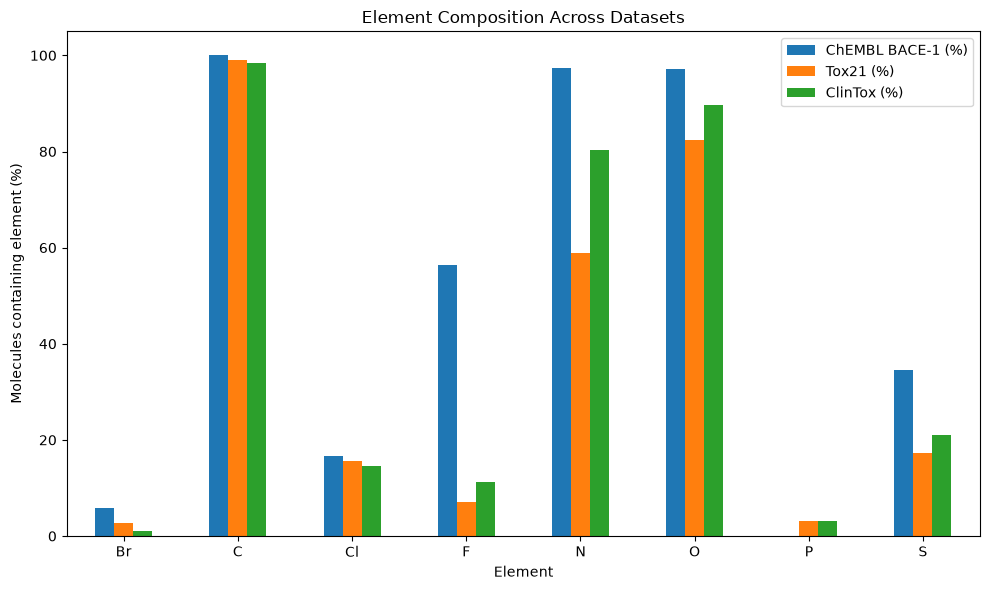

In [34]:
common_elements = [
    "C", "N", "O", "F",
    "P", "S", "Cl", "Br"
]

plot_df = (
    element_comparison_df[
        element_comparison_df["Element"].isin(common_elements)
    ]
    .set_index("Element")
    [
        [
            "ChEMBL BACE-1 (%)",
            "Tox21 (%)",
            "ClinTox (%)"
        ]
    ]
)

plot_df.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.ylabel("Molecules containing element (%)")
plt.xlabel("Element")
plt.title("Element Composition Across Datasets")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [35]:
summary_df = pd.DataFrame({
    "Dataset": [
        "ChEMBL BACE-1",
        "Tox21",
        "ClinTox"
    ],
    "Valid molecules": [
        chembl_molecule_df["elements"].notna().sum(),
        tox21_df["elements"].notna().sum(),
        clintox_df["elements"].notna().sum()
    ],
    "Invalid SMILES": [
        chembl_molecule_df["elements"].isna().sum(),
        tox21_df["elements"].isna().sum(),
        clintox_df["elements"].isna().sum()
    ],
    "Unique elements": [
        len(chembl_unique),
        len(tox21_unique),
        len(clintox_unique)
    ]
})

display(summary_df)

,Dataset,Valid molecules,Invalid SMILES,Unique elements
0,ChEMBL BACE-1,8117,0,14
1,Tox21,7823,8,50
2,ClinTox,1480,4,29


In [36]:
# Elements exclusive to each dataset
chembl_only = chembl_set - tox21_set - clintox_set
tox21_only = tox21_set - chembl_set - clintox_set
clintox_only = clintox_set - chembl_set - tox21_set

# Elements shared with at least one other dataset,
# but not shared by all three
chembl_partial_overlap = chembl_set - shared_elements - chembl_only
tox21_partial_overlap = tox21_set - shared_elements - tox21_only
clintox_partial_overlap = clintox_set - shared_elements - clintox_only

element_overlap_summary = pd.DataFrame({
    "Dataset": [
        "ChEMBL BACE-1",
        "Tox21",
        "ClinTox"
    ],

    "Total unique elements": [
        len(chembl_set),
        len(tox21_set),
        len(clintox_set)
    ],

    "Shared by all 3": [
        len(shared_elements),
        len(shared_elements),
        len(shared_elements)
    ],

    "Shared by all 3 (%)": [
        len(shared_elements) / len(chembl_set) * 100,
        len(shared_elements) / len(tox21_set) * 100,
        len(shared_elements) / len(clintox_set) * 100
    ],

    "Unique to dataset": [
        len(chembl_only),
        len(tox21_only),
        len(clintox_only)
    ],

    "Unique to dataset (%)": [
        len(chembl_only) / len(chembl_set) * 100,
        len(tox21_only) / len(tox21_set) * 100,
        len(clintox_only) / len(clintox_set) * 100
    ],

    "Partial overlap": [
        len(chembl_partial_overlap),
        len(tox21_partial_overlap),
        len(clintox_partial_overlap)
    ],

    "Partial overlap (%)": [
        len(chembl_partial_overlap) / len(chembl_set) * 100,
        len(tox21_partial_overlap) / len(tox21_set) * 100,
        len(clintox_partial_overlap) / len(clintox_set) * 100
    ]
})

# Round percentages for readability
percentage_columns = [
    "Shared by all 3 (%)",
    "Unique to dataset (%)",
    "Partial overlap (%)"
]

element_overlap_summary[percentage_columns] = (
    element_overlap_summary[percentage_columns].round(2)
)

display(element_overlap_summary)

,Dataset,Total unique elements,Shared by all 3,Shared by all 3 (%),Unique to dataset,Unique to dataset (%),Partial overlap,Partial overlap (%)
0,ChEMBL BACE-1,14,13,92.86,0,0.0,1,7.14
1,Tox21,50,13,26.00,22,44.0,15,30.00
2,ClinTox,29,13,44.83,2,6.9,14,48.28


### Element-Type Overlap Summary

This table compares the overlap in **unique element types** across the three datasets.

- **Shared by all 3** represents elements that appear in ChEMBL BACE-1, Tox21, and ClinTox.
- **Unique to dataset** represents elements that appear only in that dataset and in neither of the other two.
- **Partial overlap** represents elements that appear in that dataset and in at least one other dataset, but not in all three.

ChEMBL BACE-1 shows the strongest overlap with the common element set: **13 of its 14 unique element types (92.86%) are shared by all three datasets**. It contains no element types that are completely unique to ChEMBL, while the remaining 7.14% are shared with only one of the other datasets.

Tox21 has the greatest elemental diversity, with **50 unique element types**. Only **26.00%** of its element types are shared by all three datasets, while **44.00% are unique to Tox21**. An additional 30.00% overlap with only one of the other datasets. This indicates that Tox21 contains a much broader variety of less-common elements.

ClinTox falls between the other two datasets, with **29 unique element types**. Of these, **44.83% are shared by all three datasets**, **6.90% are unique to ClinTox**, and **48.28% partially overlap with one other dataset**.

Overall, ChEMBL BACE-1 is the most compositionally concentrated in the shared element set, while Tox21 is the most elementally diverse. ClinTox shows moderate overlap with both datasets. These differences suggest that the datasets share a common set of major elements but vary in the diversity of less-common element types they contain.

In [37]:
def atom_frequency_percentages(element_series):
    counts = Counter()

    for molecule_elements in element_series.dropna():
        counts.update(molecule_elements)

    total_atoms = sum(counts.values())

    percentages = {
        element: (count / total_atoms) * 100
        for element, count in counts.items()
    }

    return counts, percentages


chembl_atom_counts, chembl_atom_pct = atom_frequency_percentages(
    chembl_molecule_df["elements"]
)

tox21_atom_counts, tox21_atom_pct = atom_frequency_percentages(
    tox21_df["elements"]
)

clintox_atom_counts, clintox_atom_pct = atom_frequency_percentages(
    clintox_df["elements"]
)

In [38]:
all_elements = sorted(
    set(chembl_atom_pct)
    | set(tox21_atom_pct)
    | set(clintox_atom_pct)
)

atom_frequency_df = pd.DataFrame({
    "Element": all_elements,
    "ChEMBL BACE-1 (%)": [
        chembl_atom_pct.get(e, 0)
        for e in all_elements
    ],
    "Tox21 (%)": [
        tox21_atom_pct.get(e, 0)
        for e in all_elements
    ],
    "ClinTox (%)": [
        clintox_atom_pct.get(e, 0)
        for e in all_elements
    ]
}).round(4)

display(atom_frequency_df)

,Element,ChEMBL BACE-1 (%),Tox21 (%),ClinTox (%)
0,Ag,0.0000,0.0007,0.0000
1,Al,0.0000,0.0000,0.0257
2,As,0.0000,0.0083,0.0051
3,Au,0.0000,0.0034,0.0026
4,B,0.0026,0.0179,0.0077
5,Ba,0.0000,0.0028,0.0000
6,Be,0.0000,0.0007,0.0000
7,Bi,0.0000,0.0014,0.0026
8,Br,0.1838,0.2623,0.0386
9,C,72.5655,73.2775,71.9140


In [39]:
shared_atom_pct = {
    "ChEMBL BACE-1": sum(
        chembl_atom_pct.get(e, 0)
        for e in shared_elements
    ),
    "Tox21": sum(
        tox21_atom_pct.get(e, 0)
        for e in shared_elements
    ),
    "ClinTox": sum(
        clintox_atom_pct.get(e, 0)
        for e in shared_elements
    )
}

unique_atom_pct = {
    "ChEMBL BACE-1": sum(
        chembl_atom_pct.get(e, 0)
        for e in chembl_only
    ),
    "Tox21": sum(
        tox21_atom_pct.get(e, 0)
        for e in tox21_only
    ),
    "ClinTox": sum(
        clintox_atom_pct.get(e, 0)
        for e in clintox_only
    )
}

partial_atom_pct = {
    "ChEMBL BACE-1": 100
        - shared_atom_pct["ChEMBL BACE-1"]
        - unique_atom_pct["ChEMBL BACE-1"],

    "Tox21": 100
        - shared_atom_pct["Tox21"]
        - unique_atom_pct["Tox21"],

    "ClinTox": 100
        - shared_atom_pct["ClinTox"]
        - unique_atom_pct["ClinTox"]
}

atom_overlap_summary = pd.DataFrame({
    "Dataset": [
        "ChEMBL BACE-1",
        "Tox21",
        "ClinTox"
    ],
    "Atoms from elements shared by all 3 (%)": [
        shared_atom_pct["ChEMBL BACE-1"],
        shared_atom_pct["Tox21"],
        shared_atom_pct["ClinTox"]
    ],
    "Atoms from dataset-unique elements (%)": [
        unique_atom_pct["ChEMBL BACE-1"],
        unique_atom_pct["Tox21"],
        unique_atom_pct["ClinTox"]
    ],
    "Atoms from partially shared elements (%)": [
        partial_atom_pct["ChEMBL BACE-1"],
        partial_atom_pct["Tox21"],
        partial_atom_pct["ClinTox"]
    ]
}).round(4)

display(atom_overlap_summary)

,Dataset,Atoms from elements shared by all 3 (%),Atoms from dataset-unique elements (%),Atoms from partially shared elements (%)
0,ChEMBL BACE-1,99.9989,0.0000,0.0011
1,Tox21,99.8967,0.0413,0.0620
2,ClinTox,99.9228,0.0283,0.0489


### Atom-Frequency Overlap Summary

This table measures how much of the **actual atomic composition** of each dataset comes from elements that are shared across the datasets.

- **Atoms from elements shared by all 3 (%)** represents the percentage of all counted atoms that belong to element types found in ChEMBL BACE-1, Tox21, and ClinTox.
- **Atoms from dataset-unique elements (%)** represents atoms belonging to element types found only in that specific dataset.
- **Atoms from partially shared elements (%)** represents atoms from element types found in two datasets, but not all three.

The results show that the elemental composition of all three datasets is overwhelmingly dominated by the same shared element types.

- **ChEMBL BACE-1:** 99.9989% of counted atoms come from elements shared by all three datasets.
- **Tox21:** 99.8967% of counted atoms come from the shared element set.
- **ClinTox:** 99.9228% of counted atoms come from the shared element set.

Although Tox21 contains many more unique element types than the other datasets, those Tox21-specific elements account for only **0.0413% of its total counted atoms**. Similarly, ClinTox-specific elements account for only **0.0283%** of its atoms. ChEMBL BACE-1 contains no dataset-unique element types.

This shows that the additional rare elements present in Tox21 and ClinTox contribute very little to the overall molecular composition of those datasets. Therefore, despite differences in the number of distinct element types present, the three datasets are **highly similar in terms of their overall atom-level elemental composition**.

This supports the idea that the rare dataset-specific elements are unlikely to represent a major compositional difference when the datasets are combined, although differences in the frequencies of individual common elements should still be considered.

In [40]:
def exclusive_element_table(element_set, counts, percentages):
    rows = []

    for element in sorted(element_set):
        rows.append({
            "Element": element,
            "Atom count": counts.get(element, 0),
            "Percentage of all atoms (%)": percentages.get(element, 0)
        })

    return pd.DataFrame(rows).sort_values(
        "Percentage of all atoms (%)",
        ascending=False
    )


tox21_unique_frequency = exclusive_element_table(
    tox21_only,
    tox21_atom_counts,
    tox21_atom_pct
)

clintox_unique_frequency = exclusive_element_table(
    clintox_only,
    clintox_atom_counts,
    clintox_atom_pct
)

print("Tox21-only elements:")
display(tox21_unique_frequency)

print("ClinTox-only elements:")
display(clintox_unique_frequency)

Tox21-only elements:


,Element,Atom count,Percentage of all atoms (%)
17,Sn,20,0.013769
1,Ba,4,0.002754
13,Ni,4,0.002754
16,Sb,4,0.002754
7,In,3,0.002065
3,Cd,3,0.002065
8,K,3,0.002065
21,Zr,2,0.001377
10,Mg,2,0.001377
5,Gd,2,0.001377


ClinTox-only elements:


,Element,Atom count,Percentage of all atoms (%)
0,Al,10,0.025743
1,Tc,1,0.002574


In [41]:
def molecules_with_unique_elements(element_series, unique_element_set):
    valid_molecules = 0
    molecules_with_unique = 0

    for molecule_elements in element_series.dropna():
        valid_molecules += 1

        if set(molecule_elements) & unique_element_set:
            molecules_with_unique += 1

    percentage = (
        molecules_with_unique / valid_molecules * 100
        if valid_molecules > 0 else 0
    )

    return molecules_with_unique, valid_molecules, percentage


chembl_unique_mol_count, chembl_valid_count, chembl_unique_mol_pct = (
    molecules_with_unique_elements(
        chembl_molecule_df["elements"],
        chembl_only
    )
)

tox21_unique_mol_count, tox21_valid_count, tox21_unique_mol_pct = (
    molecules_with_unique_elements(
        tox21_df["elements"],
        tox21_only
    )
)

clintox_unique_mol_count, clintox_valid_count, clintox_unique_mol_pct = (
    molecules_with_unique_elements(
        clintox_df["elements"],
        clintox_only
    )
)

In [42]:
unique_element_molecule_summary = pd.DataFrame({
    "Dataset": [
        "ChEMBL BACE-1",
        "Tox21",
        "ClinTox"
    ],
    "Valid molecules": [
        chembl_valid_count,
        tox21_valid_count,
        clintox_valid_count
    ],
    "Molecules containing dataset-unique element": [
        chembl_unique_mol_count,
        tox21_unique_mol_count,
        clintox_unique_mol_count
    ],
    "Molecules containing dataset-unique element (%)": [
        chembl_unique_mol_pct,
        tox21_unique_mol_pct,
        clintox_unique_mol_pct
    ]
})

unique_element_molecule_summary[
    "Molecules containing dataset-unique element (%)"
] = unique_element_molecule_summary[
    "Molecules containing dataset-unique element (%)"
].round(4)

display(unique_element_molecule_summary)

,Dataset,Valid molecules,Molecules containing dataset-unique element,Molecules containing dataset-unique element (%)
0,ChEMBL BACE-1,8117,0,0.0000
1,Tox21,7823,57,0.7286
2,ClinTox,1480,3,0.2027
